# Болгарский корпус: отбор и слепой аудит

Цель — подготовить 1 000 000 документов для обучения с нуля и сравнить исходный FineWeb-2, опубликованный HQ-Plus и итоговый отбор. Классификатор повторно не запускается; модели и токенизатор здесь не обучаются.

Используем [FineWeb-2](https://huggingface.co/datasets/HuggingFaceFW/fineweb-2) и [FineWeb2-HQ-Plus](https://huggingface.co/datasets/epfml/FineWeb2-HQ-Plus). Их точные ревизии записаны в manifest. `quality_score` — критерий отбора, а не независимая оценка улучшения. Он основан на первых 512 токенах XLM-R; аудит длинных документов проверяет также середину и конец.

Все результаты ниже вычисляются из сохранённых артефактов. Повторное открытие ноутбука не скачивает и не переписывает корпус.

Код вынесен в пакет `src`; установите его через `bash scripts/setup.sh l40` (или профиль `5080`). Сохранённые результаты относятся к прежнему запуску. Пути берутся из `src.paths` и учитывают `MONOLM_ARTIFACTS`. Команды воспроизведения — в `task1/README.md`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

from src.paths import TASK as ROOT, ARTIFACTS
LABELS = {"raw": "FineWeb-2", "hq": "HQ-Plus", "top": "Top 1M"}

def read_json(relative):
    return json.loads((ARTIFACTS / relative).read_text())

def figure(name):
    display(Image(filename=str(ARTIFACTS / "figures" / name)))

manifest = read_json("corpus/manifest.json")
verification = read_json("corpus/verification.json")
stats = read_json("statistics/summary.json")
audit = read_json("audit_failures/summary.json")
previous_audit = read_json("audit/summary.json")
assert verification["passed"]


## Подготовка и воспроизводимость

Убраны только пустые тексты, точные дубликаты после NFC / нормализации переводов строк / strip и совпадения с отложенными документами. Нормализация применяется только для хеша; обучающий текст не меняется. Среди дублей остаётся максимальный score, затем минимальный `id`.

После очистки взят миллион по `quality_score DESC, id ASC`, затем перемешан с seed 42. Validation и test — по 5 000 уникальных документов официального test FineWeb-2. Разделение проверено по ID и хешу; близкие, но не точные копии дополнительно не искались.

В карточке HQ-Plus упомянута версия FineWeb-2 `v2.1.1`, но такой отдельной ветки в репозитории нет. Загрузки закреплены за фактическими commit SHA, показанными ниже. Исходные 12 train-файлов уже находились локально; повторно они не скачивались.

Воспроизведение из каталога `task1`:
```bash
bash scripts/pipeline.sh corpus-analysis
# Затем внешняя разметка пакетов и разбор расхождений.
../venv/bin/python -m src audit summarize --rubric strict
../venv/bin/python -m src audit summarize --rubric failures
```
Аудит сохраняется как отдельный результат оценщиков; скрипт не подменяет его эвристикой. Проверка корпуса: `../venv/bin/python -m src corpus verify`. Основной обучающий пайплайн не зависит от наличия оценок аудита.

In [2]:
display(pd.Series(manifest["source_rows"], name="Строк в источниках").to_frame())
display(pd.Series({"FineWeb-2 revision": manifest["raw_revision"],
                   "HQ-Plus revision": manifest["hq_revision"],
                   "seed": manifest["seed"],
                   "quality threshold": manifest["quality_threshold"]}, name="Значение").to_frame())
display(pd.Series(manifest["counts"], name="Документы").to_frame())
display(pd.DataFrame(verification["splits"]).T)
display(pd.DataFrame(manifest["files"])[["path", "rows", "bytes"]])


,Строк в источниках
raw,25994731
hq,2561554
official_test,36933


,Значение
FineWeb-2 revision,af9c13333eb981300149d5ca60a8e9d659b276b9
HQ-Plus revision,146690ef88e86e6d728a03ea6f6d85037d8cf9fa
seed,42
quality threshold,0.960853


,Документы
published_hq,2561554
empty_removed,0
exact_duplicates_removed,0
holdout_overlaps_removed,0
eligible,2561554
repeated_ids_observed,1


,documents,characters,whitespace_words,utf8_bytes
train,1000000,5157500445,797609185,9206548168
validation,5000,16015758,2497924,28629461
test,5000,16558249,2601552,29633486


,path,rows,bytes
0,corpus/train/00.parquet,100000,282399314
1,corpus/train/01.parquet,100000,283786769
2,corpus/train/02.parquet,100000,278991620
3,corpus/train/03.parquet,100000,279605674
4,corpus/train/04.parquet,100000,279446044
5,corpus/train/05.parquet,100000,281934004
6,corpus/train/06.parquet,100000,281015319
7,corpus/train/07.parquet,100000,279231985
8,corpus/train/08.parquet,100000,279247319
9,corpus/train/09.parquet,100000,278702383


`whitespace_words` — непустые элементы `str.split()`, а не токены модели. Точное число токенов появится только после обучения собственного токенизатора. Байты — UTF-8 самого текста, без parquet-метаданных.

## Дизайн сравнения

Для каждого корпуса выбраны 10 000 строк равномерно без возвращения по глобальным индексам всех parquet-файлов. Читаются только нужные row groups и колонки. Из каждой выборки до оценки выделены 200 документов для слепого аудита.

Автоматические показатели ниже — описательные характеристики. Кириллица не отличает болгарский от русского, исходный `language_score` не является независимой проверкой, а естественная пунктуация попадает в долю прочих символов. Большее разнообразие слов само по себе также не означает более качественный текст.

Опубликованный `language_score` сохраняется без округления и ограничения диапазона; некоторые значения немного больше 1. Он почти насыщен и слабо различает эти выборки.

group,HQ-Plus,FineWeb-2,Top 1M
metric,,,
cyrillic_letter_fraction,0.968022,0.966707,0.969183
digit_fraction,0.009684,0.011493,0.010932
letter_fraction,0.803930,0.801322,0.802261
n_chars,5659.796600,3342.540700,5062.824200
n_words,876.812500,522.255200,783.873800
other_symbol_fraction,0.031218,0.031250,0.031568
repeated_5gram_fraction,0.007689,0.008601,0.006719
repeated_line_char_fraction,0.001640,0.002404,0.001420


,mean,median,p90,p99
group,,,,
FineWeb-2,0.999671,1.000004,1.000009,1.00001
HQ-Plus,0.999895,1.000004,1.000009,1.00001
Top 1M,0.999938,1.000004,1.000009,1.00001


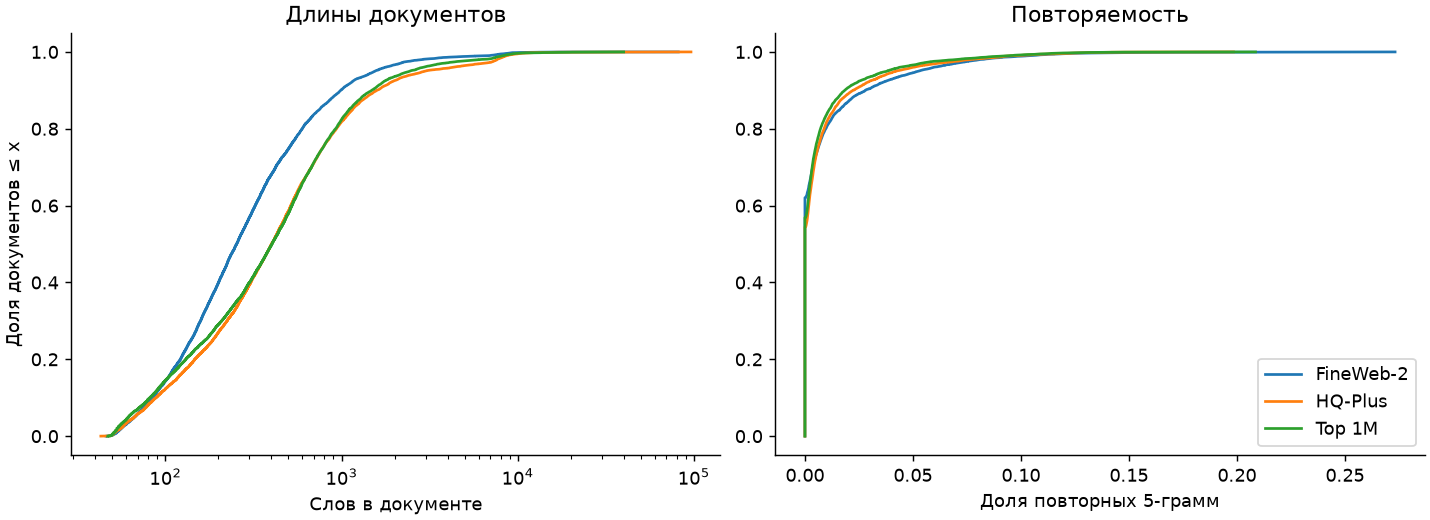

In [3]:
metrics = pd.DataFrame(stats["metrics"])
selected_metrics = ["n_words", "n_chars", "repeated_line_char_fraction", "repeated_5gram_fraction",
                    "letter_fraction", "cyrillic_letter_fraction", "digit_fraction", "other_symbol_fraction"]
display(metrics.loc[metrics.metric.isin(selected_metrics)].pivot(index="metric", columns="group", values="mean").rename(columns=LABELS))
display(metrics.loc[metrics.metric == "language_score", ["group", "mean", "median", "p90", "p99"]].set_index("group").rename(index=LABELS))
figure("lengths_repetition.png")


## Источники и словарь

Доли сайтов посчитаны по hostname. Десять крупнейших выбираются отдельно по числу документов и по числу символов; это могут быть разные наборы сайтов. Лексическое сравнение использует ровно 1 млн слов на корпус после случайного перемешивания документов: Unicode-буквы с допустимыми внутренними апострофами и дефисами, `casefold`. Это определение отличается от счётчика `whitespace_words`.

,unique_hostnames,top10_document_share,top10_character_share
group,,,
FineWeb-2,5165,0.0808,0.079674
HQ-Plus,4456,0.0661,0.095831
Top 1M,4006,0.0889,0.100934


,words,vocabulary,hapax_types,hapax_type_share,hapax_token_share
group,,,,,
FineWeb-2,1000000,90497,45194,0.499398,0.045194
HQ-Plus,1000000,89378,44800,0.501242,0.044800
Top 1M,1000000,95470,48322,0.506149,0.048322


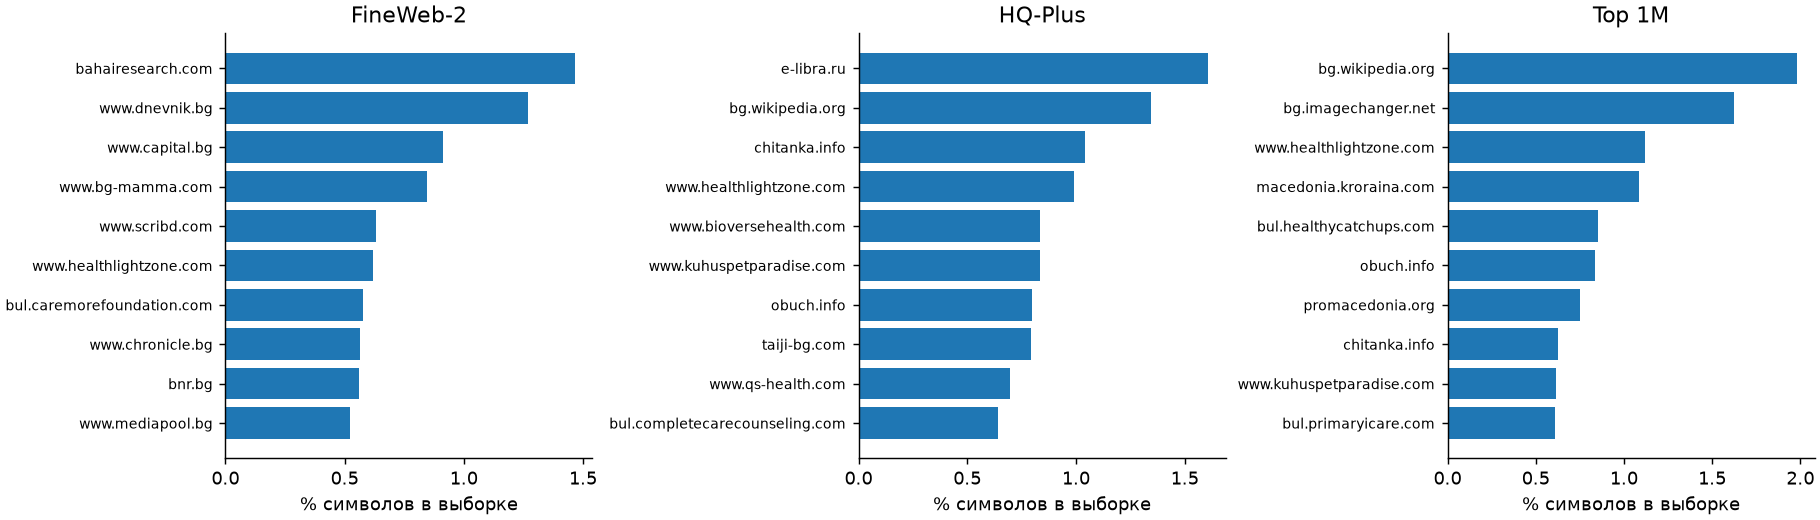

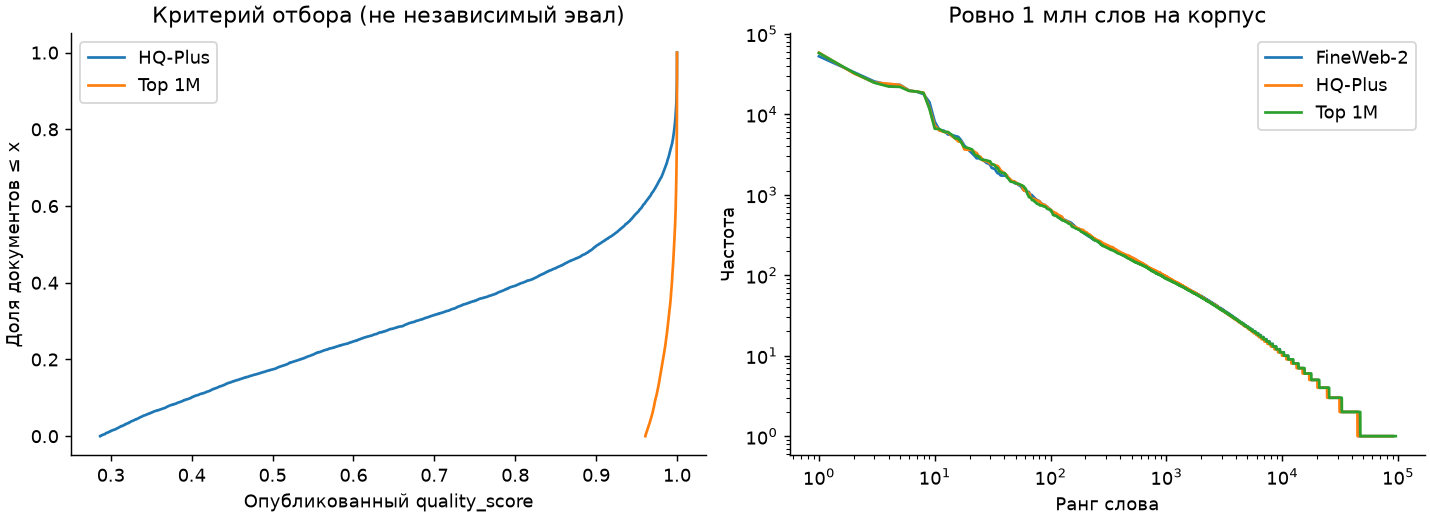

FineWeb-2        HQ-Plus        Top 1M       
        word  count    word  count   word  count
1         на  52501      на  58315     на  57725
2          и  33354       и  32181      и  32820
3         да  25604      да  24806      в  24666
4          в  23253       в  23944     се  22084
5         за  23220      се  23082     да  21881
6         се  19802      от  19621     от  19485
7         от  19025      за  19186      е  19157
8          е  17803       е  18530     за  18413
9          с  14158       с  12051      с  11676
10        не   8102      не   7217     са   6607
11        са   6319      че   6266     не   6560
12        че   6260      са   6044   като   6044
13      това   5607    това   5939     че   6033
14        ще   5528    като   5366   това   5565
15        си   5361      си   5003     си   5015
16        по   5234      по   4591     по   4964
17      като   4690     или   4538    или   4416
18       или   4089   които   3659   през   3916
19     които   3767     при   3626      г   3836
20        до   3495      до   3617  които   3755

In [4]:
display(pd.DataFrame(stats["domains"]).set_index("group").rename(index=LABELS))
display(pd.DataFrame(stats["lexical"]).set_index("group").rename(index=LABELS))
figure("domains.png")
figure("scores_words.png")
frequent = {LABELS[group]: pd.read_parquet(ARTIFACTS / "statistics" / f"{group}_vocabulary.parquet").head(20)
            for group in LABELS}
display(pd.concat(frequent, axis=1).set_axis(range(1, 21)))


## Повторный слепой аудит: только явный брак

По запросу пользователя критерий пересмотрен после обсуждения первого аудита. Проверяются **те же 600 документов** (по 200 на корпус), с новыми непрозрачными ID и новым распределением между тремя оценщиками в свежих контекстах. Они не видят прежних оценок, названий корпусов, URL или score. 60 документов получают вторую оценку; расхождения разбираются отдельно.

Теперь отклоняем только:

| Дефект | Основание для отклонения |
|---|---|
| `wrong_language` | Явно преобладает другой язык; иностранные цитаты и названия допустимы |
| `garbage` | Почти весь материал — мусор, ориентир около 80%; полноценного полезного текста почти нет |
| `corruption` | Повреждения делают большую часть текста нечитаемой |
| `unintelligible` | В большинстве предполагаемой прозы невозможно восстановить основные сообщения |

**Понятный, но корявый перевод проходит.** Отдельные странные слова, опечатки, мусорный хвост при содержательной статье, короткие объявления и осмысленные списки не являются основанием для отказа. Естественность, образовательная ценность и литературность отдельно не оцениваются.

Решения: `pass` — явный брак не обнаружен, `reject` — подтверждён хотя бы один дефект, `uncertain` — недостаточно уверенности. Неясные случаи показаны отдельно и не засчитываются как pass.

Тексты до 6 000 символов показаны целиком, длинные — тремя фрагментами по 2 000 символов. Разрывы между фрагментами не штрафуются. Интервалы: 2 000 bootstrap-повторов с общими весами для одинаковых документов. Это доли документов; они не взвешены по токенам.

**Ограничение:** рубрика изменена после просмотра прежних результатов. Это исследовательская переоценка того же материала, а не независимое подтверждение улучшения корпуса. Подагенты одной модели не заменяют носителей языка; интервалы не отражают систематические ошибки оценщиков. При нуле наблюдаемых дефектов bootstrap может дать [0; 0], что не доказывает отсутствие редкого брака во всём корпусе.


Когда брак редок, высокий процент согласия может почти целиком состоять из совпадений pass/pass. Он сам по себе не подтверждает, что оценщики хорошо находят дефекты; состав пар решений показан ниже.

,Проверено документов
HQ-Plus,200
FineWeb-2,200
Top 1M,200


count  estimate     low    high
group metric                                    
raw   pass         196      98.0   95.81   99.53
      reject         2       1.0    0.00    2.62
      uncertain      2       1.0    0.00    2.59
hq    pass         200     100.0  100.00  100.00
      reject         0       0.0    0.00    0.00
      uncertain      0       0.0    0.00    0.00
top   pass         199      99.5   98.38  100.00
      reject         1       0.5    0.00    1.62
      uncertain      0       0.0    0.00    0.00

,difference,low,high
comparison,,,
hq - raw,-1.0,-2.62,0.00
top - raw,-0.5,-2.26,1.09
top - hq,0.5,0.00,1.62


,Значение
documents,60.0
decision_agreements,60.0
decision_agreement,1.0
adjudicated_documents,0.0


,Двойные оценки
pass / pass,60


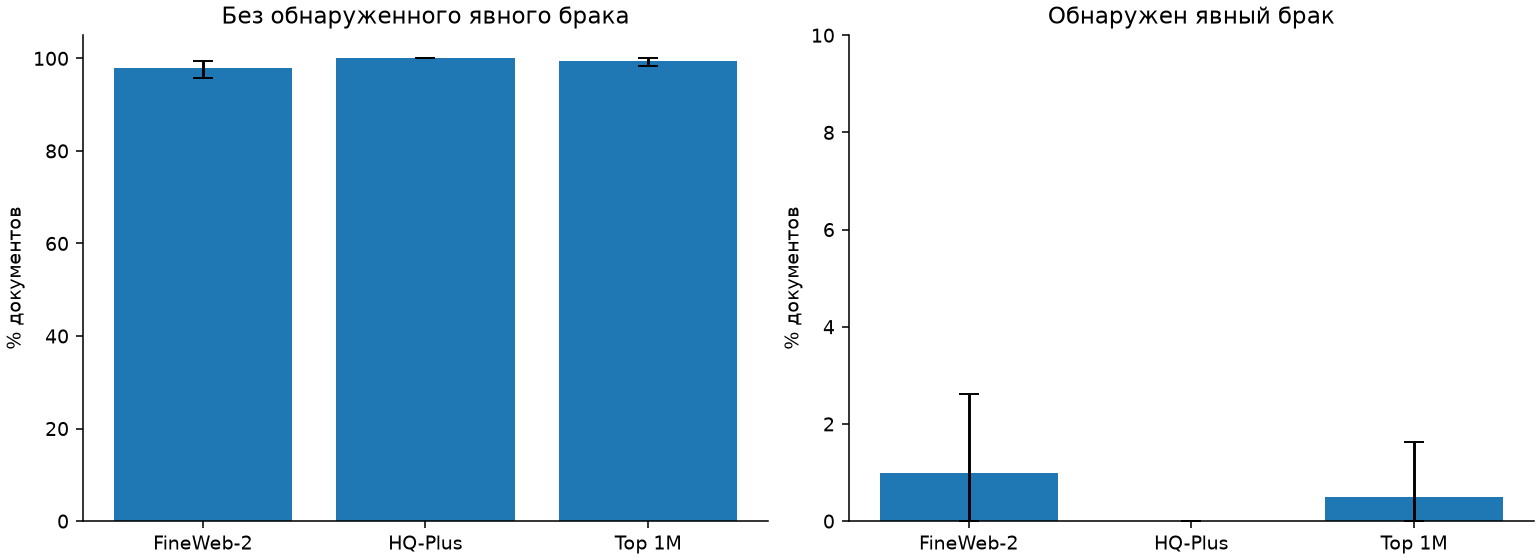

In [5]:
display(pd.Series(audit["coverage"]["memberships_per_group"], name="Проверено документов").rename(index=LABELS).to_frame())
intervals = pd.DataFrame(audit["intervals"])
comparisons = pd.DataFrame(audit["comparisons"])
outcomes = intervals.loc[intervals.metric.isin(["pass", "reject", "uncertain"])].copy()
for column in ["estimate", "low", "high"]:
    outcomes[column] = (outcomes[column] * 100).round(2)
display(outcomes.set_index(["group", "metric"]))
display(comparisons.loc[comparisons.metric == "reject", ["comparison", "difference", "low", "high"]].set_index("comparison").mul(100).round(2))
display(pd.Series(audit["agreement"], name="Значение").to_frame())
display(pd.Series(audit["decision_pairs"], name="Двойные оценки").to_frame())
figure("audit_failures.png")


In [6]:
def percentage_table(names):
    rows = intervals.loc[intervals.metric.isin(names)].copy()
    rows["Доля, % [95% ДИ]"] = rows.apply(lambda r: f"{100*r.estimate:.1f} [{100*r.low:.1f}; {100*r.high:.1f}]", axis=1)
    result = rows.pivot(index="metric", columns="group", values="Доля, % [95% ДИ]").reindex(columns=LABELS).rename(columns=LABELS)
    delta = comparisons.loc[(comparisons.comparison == "top - raw") & comparisons.metric.isin(names)].set_index("metric")
    result["Top − raw, п.п. [95% ДИ]"] = delta.apply(lambda r: f"{100*r.difference:+.1f} [{100*r.low:+.1f}; {100*r.high:+.1f}]", axis=1)
    return result

display(percentage_table(["wrong_language", "garbage", "corruption", "unintelligible"]))


group,FineWeb-2,HQ-Plus,Top 1M,"Top − raw, п.п. [95% ДИ]"
metric,,,,
corruption,0.0 [0.0; 0.0],0.0 [0.0; 0.0],0.0 [0.0; 0.0],+0.0 [+0.0; +0.0]
garbage,0.5 [0.0; 1.6],0.0 [0.0; 0.0],0.5 [0.0; 1.6],+0.0 [-1.5; +1.5]
unintelligible,0.0 [0.0; 0.0],0.0 [0.0; 0.0],0.0 [0.0; 0.0],+0.0 [+0.0; +0.0]
wrong_language,0.5 [0.0; 1.6],0.0 [0.0; 0.0],0.0 [0.0; 0.0],-0.5 [-1.6; +0.0]


## Примеры явного брака и неясных случаев

Первые по непрозрачному ID три случая `reject`/`uncertain` на корпус. Полные предоставленные оценщикам тексты и все решения сохранены в `artifacts/audit_failures/`. Если примеров меньше трёх, показаны все найденные.


In [7]:
resolved = pd.read_parquet(ARTIFACTS / "audit_failures/resolved.parquet")
examples = resolved.loc[resolved.decision.ne("pass")].sort_values("audit_id").groupby("group", group_keys=False).head(3)
with pd.option_context("display.max_colwidth", 220):
    display(examples[["group", "audit_id", "decision", "failures", "confidence", "reason"]])


,group,audit_id,decision,failures,confidence,reason
547,top,71d4715bb1312bde,reject,[garbage],medium,"Практически весь текст — ошибка API «Incorrect deliveryAreaId» и служебный шаблон заказа еды с пустым «например в .», без содержательных сведений о ресторанах."
61,raw,873a9f07128cbd39,reject,[garbage],high,"Практически весь текст — названия разделов о шторах, «Кошница», подписка на бюллетень JYSK и социальные ссылки; содержательной статьи нет."
169,raw,b7360f03da59d710,uncertain,[],medium,"Числовые характеристики катушки и часть условий понятны, но несколько ключевых фраз вроде «червей съоръжения клапана на цилиндър» и «осигури огромен и дори да се разруши» разрушены; неясно, преобладает ли непонятная ..."
64,raw,ef654cfe8b769ae2,uncertain,[],medium,"Начало «местата ... gleydery посетили копия» и описание сюжета сильно разрушены; критика графики и рекомендация фанатам понятны, граница большинства неясна."


## Выводы и готовые файлы

In [8]:
primary = comparisons.loc[(comparisons.comparison == "top - raw") & (comparisons.metric == "reject")].iloc[0]
extra = comparisons.loc[(comparisons.comparison == "top - hq") & (comparisons.metric == "reject")].iloc[0]
if primary.high < 0:
    verdict = "в итоговой выборке меньше явного брака по новой рубрике"
elif primary.low > 0:
    verdict = "в итоговой выборке больше явного брака по новой рубрике"
else:
    verdict = "различие доли явного брака между исходной и итоговой выборками не подтверждено"
rates = intervals.loc[intervals.metric == "reject"].set_index("group").estimate
concentration = pd.DataFrame(stats["domains"]).set_index("group")
text = f"""**{verdict.capitalize()}**. Доля явного брака: FineWeb-2 — {rates['raw']*100:.1f}%, HQ-Plus — {rates['hq']*100:.1f}%, Top 1M — {rates['top']*100:.1f}%.

Разница Top 1M − FineWeb-2: {primary.difference*100:+.1f} п.п., 95% ДИ [{primary.low*100:+.1f}; {primary.high*100:+.1f}]. Разница Top 1M − HQ-Plus: {extra.difference*100:+.1f} п.п., 95% ДИ [{extra.low*100:+.1f}; {extra.high*100:+.1f}]. Для этого показателя меньше — лучше. Неясные случаи не входят в подтверждённый брак и показаны отдельно.

Корпус не менялся: 1 000 000 train-документов и по 5 000 validation/test, с прежними проверенными SHA-256. Изменился вопрос к оценщикам: теперь ищем только явный брак. Высокая доля pass не означает безупречный болгарский, отсутствие ошибок перевода или доказанную пользу для обученной LLM.

Изменение состава сохраняется: доля символов десяти крупнейших hostname — {concentration.loc['raw', 'top10_character_share']*100:.1f}% в исходной выборке и {concentration.loc['top', 'top10_character_share']*100:.1f}% в итоговой. Данные и файл manifest находятся в `artifacts/corpus/`.

Первый аудит со строгим требованием к естественности сохранён в `artifacts/audit/`, его выполненный ноутбук — в `artifacts/reports/dataset_audit_v1.ipynb`. Новые решения — в `artifacts/audit_failures/`. Это разные критерии на одной выборке; смена показателя не является улучшением самого корпуса."""
display(Markdown(text))


**Различие доли явного брака между исходной и итоговой выборками не подтверждено**. Доля явного брака: FineWeb-2 — 1.0%, HQ-Plus — 0.0%, Top 1M — 0.5%.

Разница Top 1M − FineWeb-2: -0.5 п.п., 95% ДИ [-2.3; +1.1]. Разница Top 1M − HQ-Plus: +0.5 п.п., 95% ДИ [+0.0; +1.6]. Для этого показателя меньше — лучше. Неясные случаи не входят в подтверждённый брак и показаны отдельно.

Корпус не менялся: 1 000 000 train-документов и по 5 000 validation/test, с прежними проверенными SHA-256. Изменился вопрос к оценщикам: теперь ищем только явный брак. Высокая доля pass не означает безупречный болгарский, отсутствие ошибок перевода или доказанную пользу для обученной LLM.

Изменение состава сохраняется: доля символов десяти крупнейших hostname — 8.0% в исходной выборке и 10.1% в итоговой. Данные и файл manifest находятся в `artifacts/corpus/`.

Первый аудит со строгим требованием к естественности сохранён в `artifacts/audit/`, его выполненный ноутбук — в `artifacts/reports/dataset_audit_v1.ipynb`. Новые решения — в `artifacts/audit_failures/`. Это разные критерии на одной выборке; смена показателя не является улучшением самого корпуса.

## Сопоставление двух рубрик

Показатели ниже отвечают на разные вопросы. Первый требует приемлемости по всем четырём оценкам, включая естественность; второй допускает понятный корявый текст и проверяет только явный брак. Жанровые метки сохранены из первого аудита и здесь не переоценивались.


In [9]:
old_rates = pd.DataFrame(previous_audit["intervals"])
old_rates = old_rates.loc[old_rates.metric == "usable"].set_index("group").estimate
new_rates = intervals.loc[intervals.metric == "pass"].set_index("group").estimate
display(pd.DataFrame({"Прошёл прежнюю строгую рубрику, %": old_rates*100,
                      "Явный брак не обнаружен, %": new_rates*100}).rename(index=LABELS).round(1))
genres = pd.DataFrame(previous_audit["genre_counts"]).pivot(index="genre", columns="group", values="count").fillna(0)
display(genres.div(200).mul(100).rename(columns=LABELS))


,"Прошёл прежнюю строгую рубрику, %","Явный брак не обнаружен, %"
group,,
FineWeb-2,85.5,98.0
HQ-Plus,72.5,100.0
Top 1M,74.0,99.5


group,HQ-Plus,FineWeb-2,Top 1M
genre,,,
commercial,9.0,26.0,5.5
discussion,2.0,4.0,2.0
education,37.0,14.5,41.0
encyclopedia,8.0,0.5,16.0
news,29.0,44.0,21.0
official,3.5,1.5,1.5
other,10.0,8.0,9.0
prose,1.5,1.5,4.0
